# ColetaCerta: previsão de solicitações de limpeza e coleta de lixo (SP156)

**Pergunta de Machine Learning:** quantas solicitações de limpeza e coleta de lixo os cidadãos vão abrir no SP156 em cada Prefeitura Regional, por dia e por semana?

**Modelo:** Random Forest (regressão).

**Dados reais:** SP156 – Solicitações, 3º trimestre de 2026 (01/07/2026 a 30/09/2026), tema "Lixo e limpeza". Fonte: Portal de Dados Abertos da Cidade de São Paulo (https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156). O arquivo foi filtrado no Google Colab pelo tema "Lixo e limpeza".

## 1. Bibliotecas
Importamos as bibliotecas de manipulação de dados (pandas, numpy), gráficos (matplotlib) e Machine Learning (scikit-learn) que serão usadas no trabalho.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

## 2. Carregamento dos dados
Carregamos o arquivo com as solicitações de "Lixo e limpeza" e conferimos o tamanho da base, os status das solicitações e a quantidade de valores vazios em cada coluna.

In [2]:
df = pd.read_csv('dados_lixo_e_limpeza.csv')
print('Linhas originais:', len(df))
print(df['Status'].value_counts())
print(df.isna().sum())

Linhas originais: 57776
Status
Finalizada      54717
Aberto           3003
Cancelada          54
Em Andamento        2
Name: count, dtype: int64
Data de Abertura             0
Data de Finalização       3005
Meio de Comunicação          0
Tema                         0
Assunto                      0
Serviço                      0
Status                       0
Órgão                        0
Logradouro                   1
Número                       1
CEP                          1
Latitude                     1
Longitude                    1
Prefeitura Operacional      40
Distrito                    17
dtype: int64


## 3. Limpeza dos dados
Convertemos a data de abertura para o formato de data, removemos as solicitações canceladas e as sem Prefeitura Regional (não dá para prever por região sem ela) e mantivemos apenas as 32 Prefeituras Regionais, descartando órgãos com pouquíssimos registros.

In [3]:
df['data'] = pd.to_datetime(df['Data de Abertura'])
df = df[df['Status'] != 'Cancelada']                       # solicitações canceladas não contam
df = df.dropna(subset=['Prefeitura Operacional'])          # sem região não dá para prever por região
contagem = df['Prefeitura Operacional'].value_counts()
regioes = contagem[contagem >= 300].index                  # fica só com as 32 prefeituras regionais
df = df[df['Prefeitura Operacional'].isin(regioes)]
print('Linhas após limpeza:', len(df), '| Regiões:', len(regioes))

Linhas após limpeza: 57540 | Regiões: 32


## 4. Tabela diária por região
Transformamos as solicitações individuais em uma contagem por dia e por região, que é o que queremos prever. Dias sem nenhuma solicitação foram preenchidos com zero e criamos variáveis de calendário: dia da semana, fim de semana, dia do mês e feriado (7 de setembro).

In [4]:
datas = pd.date_range('2026-07-01', '2026-09-30')
diario = df.groupby(['data','Prefeitura Operacional']).size().rename('solicitacoes').reset_index()
idx = pd.MultiIndex.from_product([datas, sorted(regioes)], names=['data','Prefeitura Operacional'])
# dias sem nenhuma solicitação precisam aparecer como 0
diario = diario.set_index(['data','Prefeitura Operacional']).reindex(idx, fill_value=0).reset_index()

diario['dia_semana'] = diario['data'].dt.dayofweek          # 0 = segunda
diario['fim_de_semana'] = (diario['dia_semana'] >= 5).astype(int)
diario['dia_mes'] = diario['data'].dt.day
diario['feriado'] = (diario['data'] == '2026-09-07').astype(int)   # Independência
diario['semana'] = diario['data'].dt.isocalendar().week.astype(int)
print(diario.shape)   # (2944, 8)
diario.head()

(2944, 8)


,data,Prefeitura Operacional,solicitacoes,dia_semana,fim_de_semana,dia_mes,feriado,semana
0,2026-07-01,ARICANDUVA-FORMOSA-CARRAO,21,2,0,1,0,27
1,2026-07-01,BUTANTA,24,2,0,1,0,27
2,2026-07-01,CAMPO LIMPO,39,2,0,1,0,27
3,2026-07-01,CAPELA DO SOCORRO,41,2,0,1,0,27
4,2026-07-01,CASA VERDE-LIMAO-CACHOEIRINHA,25,2,0,1,0,27


## 5. Análise exploratória
Os gráficos mostram o volume diário na cidade, a média de solicitações por dia da semana e as 10 regiões com mais solicitações. Isso ajuda a entender o padrão dos dados antes de treinar o modelo.

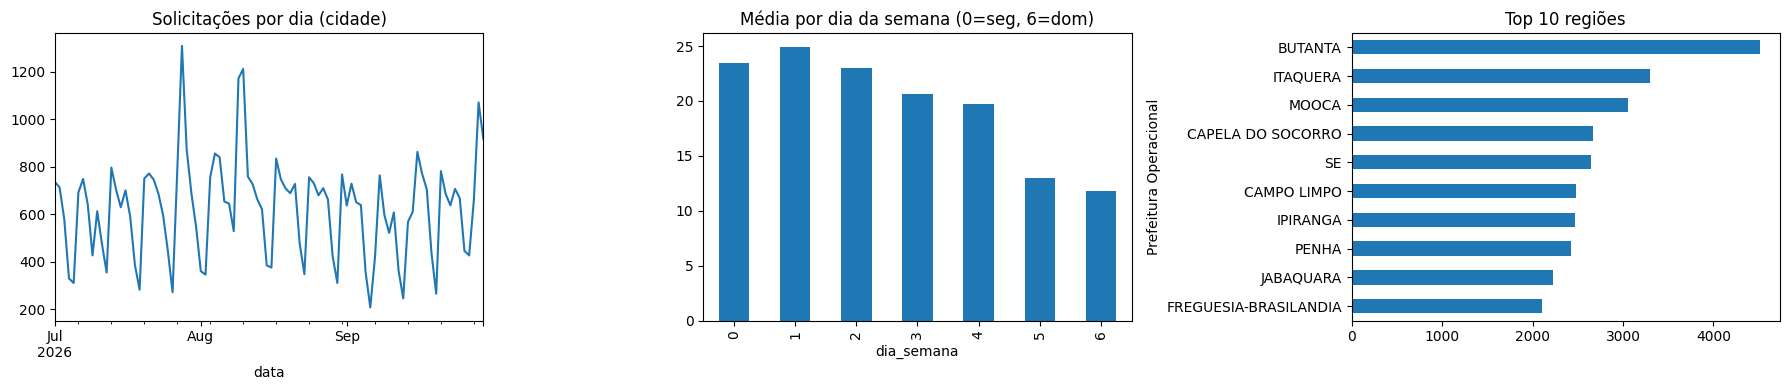

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
diario.groupby('data')['solicitacoes'].sum().plot(ax=ax[0], title='Solicitações por dia (cidade)')
diario.groupby('dia_semana')['solicitacoes'].mean().plot.bar(ax=ax[1], title='Média por dia da semana (0=seg, 6=dom)')
diario.groupby('Prefeitura Operacional')['solicitacoes'].sum().sort_values().tail(10).plot.barh(ax=ax[2], title='Top 10 regiões')
plt.tight_layout(); plt.show()

**O que observamos nos gráficos:**

- **Volume diário na cidade:** o número de solicitações varia bastante de um dia para o outro, em um padrão que se repete toda semana, com quedas regulares. A maior parte dos dias fica entre 400 e 800 solicitações, e há um pico isolado acima de 1.300 no início de agosto.
- **Dia da semana:** as solicitações são mais frequentes de segunda a quarta-feira (cerca de 23 a 25 por dia, por região) e caem ao longo da semana, chegando a cerca de 13 no sábado e 12 no domingo. Por isso o dia da semana e o fim de semana são variáveis importantes para o modelo.
- **Regiões:** Butantã é a região com mais solicitações (cerca de 4.500 no trimestre), bem à frente de Itaquera (cerca de 3.300) e Mooca (cerca de 3.000). As demais do Top 10 ficam entre 2.000 e 2.700 solicitações. Parte da vantagem de Butantã vem de um pico atípico em agosto, tratado mais adiante.

## 6. Tratamento de picos atípicos (outliers)
Alguns dias tiveram volumes muito acima do normal, como Butantã em 09/08, com 953 solicitações em um dia. Esses picos distorcem o aprendizado, então removemos do treino os valores muito acima do padrão de cada região (regra do IQR), calculada apenas com dados de treino. A base de teste não foi alterada, para avaliar o modelo em condições reais. A causa desses picos não é identificável nos dados.

Picos removidos do treino: 9
           data Prefeitura Operacional  solicitacoes
1249 2026-08-09                BUTANTA           953
1281 2026-08-10                BUTANTA           524
883  2026-07-28                  PENHA           260
897  2026-07-29                BUTANTA           160
881  2026-07-28                  MOOCA           152


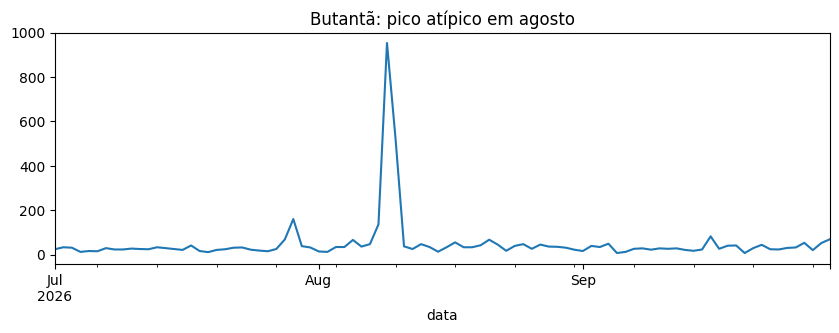

In [7]:
treino_mask = diario['data'] < '2026-09-01'
q = diario[treino_mask].groupby('Prefeitura Operacional')['solicitacoes'].quantile([0.25, 0.75]).unstack()
limite = q[0.75] + 3 * (q[0.75] - q[0.25])                  # regra do IQR, calculada só no treino
diario['limite'] = diario['Prefeitura Operacional'].map(limite)
pico = (diario['solicitacoes'] > diario['limite']) & treino_mask
print('Picos removidos do treino:', pico.sum())
print(diario[pico].sort_values('solicitacoes', ascending=False).head(5)[['data','Prefeitura Operacional','solicitacoes']])

diario[diario['Prefeitura Operacional']=='BUTANTA'].set_index('data')['solicitacoes'].plot(figsize=(10,3), title='Butantã: pico atípico em agosto')
plt.show()

dados = diario[~pico].copy()   # os picos saem só do treino. O teste fica intocado.

## 7. Variáveis e divisão treino/teste
Transformamos a região em colunas numéricas (one-hot encoding). Como são dados ao longo do tempo, a divisão respeita a ordem cronológica: treino de 01/07 a 31/08 e teste em setembro. Assim o modelo nunca "vê o futuro" durante o treino.

In [8]:
cols = ['Prefeitura Operacional','dia_semana','fim_de_semana','dia_mes','feriado']
X = pd.get_dummies(dados[cols], columns=['Prefeitura Operacional'])
y = dados['solicitacoes']
tr = dados['data'] < '2026-09-01'
X_tr, X_te, y_tr, y_te = X[tr], X[~tr], y[tr], y[~tr]
print(X_tr.shape, X_te.shape)   # (1975, 36) e (960, 36)

(1975, 36) (960, 36)


## 8. Treino com diferentes hiperparâmetros
Testamos 18 combinações de 3 hiperparâmetros do Random Forest: número de árvores (n_estimators), profundidade máxima (max_depth) e tamanho mínimo das folhas (min_samples_leaf). A validação cruzada (TimeSeriesSplit, que respeita a ordem do tempo) foi feita somente na base de treino, e o critério de escolha foi o menor erro médio absoluto (MAE).

In [9]:
grid = {'n_estimators': [100, 300], 'max_depth': [5, 10, None], 'min_samples_leaf': [1, 5, 10]}
gs = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1), grid,
                  cv=TimeSeriesSplit(5), scoring='neg_mean_absolute_error',
                  return_train_score=True)
gs.fit(X_tr, y_tr)

res = pd.DataFrame(gs.cv_results_)
res['MAE treino (CV)'] = -res['mean_train_score']
res['MAE validação (CV)'] = -res['mean_test_score']
tabela_hp = res[['param_n_estimators','param_max_depth','param_min_samples_leaf',
                 'MAE treino (CV)','MAE validação (CV)']].sort_values('MAE validação (CV)').round(2)
display(tabela_hp)
print('Melhores parâmetros:', gs.best_params_)
m = gs.best_estimator_

,param_n_estimators,param_max_depth,param_min_samples_leaf,MAE treino (CV),MAE validação (CV)
12,100,None,1,1.91,5.64
13,300,None,1,1.89,5.65
14,100,None,5,4.76,5.67
15,300,None,5,4.75,5.67
6,100,10,1,4.77,5.74
7,300,10,1,4.76,5.75
9,300,10,5,5.51,5.99
8,100,10,5,5.52,5.99
17,300,None,10,5.83,6.32
16,100,None,10,5.85,6.35


Melhores parâmetros: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}


## 9. Resultados: treino e teste lado a lado
Comparamos MAE, RMSE e R² no treino e no teste. Quando o desempenho no treino é muito melhor do que no teste, há overfitting (o modelo "decorou" o treino). Também comparamos com um modelo simples de referência (média histórica por região e dia da semana) para saber se o Random Forest realmente agrega valor.

,Treino,Teste
MAE,1.932,6.619
RMSE,2.690,9.221
R2,0.947,0.439


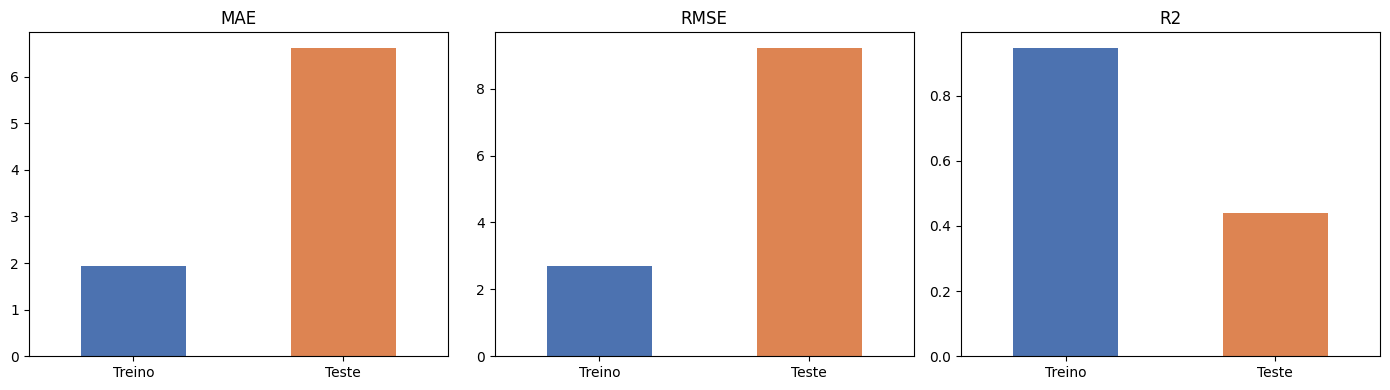

Baseline (média região+dia): {'MAE': 6.378, 'RMSE': 8.793, 'R2': 0.49}


In [10]:
def met(yt, p):
    return {'MAE': mean_absolute_error(yt, p), 'RMSE': root_mean_squared_error(yt, p), 'R2': r2_score(yt, p)}

tabela = pd.DataFrame({'Treino': met(y_tr, m.predict(X_tr)), 'Teste': met(y_te, m.predict(X_te))}).round(3)
display(tabela)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, metrica in zip(ax, ['MAE','RMSE','R2']):
    tabela.loc[metrica].plot.bar(ax=a, color=['#4c72b0','#dd8452'], title=metrica)
    a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

# Comparação com um modelo "ingênuo": média histórica por região e dia da semana
base = dados[tr].groupby(['Prefeitura Operacional','dia_semana'])['solicitacoes'].mean()
pb = dados[~tr].set_index(['Prefeitura Operacional','dia_semana']).index.map(base)
print('Baseline (média região+dia):', {k: round(v,3) for k,v in met(y_te, pb).items()})

## 10. Visão semanal e importância das variáveis
A API do ColetaCerta devolve uma previsão por semana, então somamos as previsões diárias de cada semana de teste e comparamos com o valor real. O gráfico de importância mostra quais variáveis mais influenciam a previsão.

Semanal: {'MAE': 20.094, 'RMSE': 27.212, 'R2': 0.74}


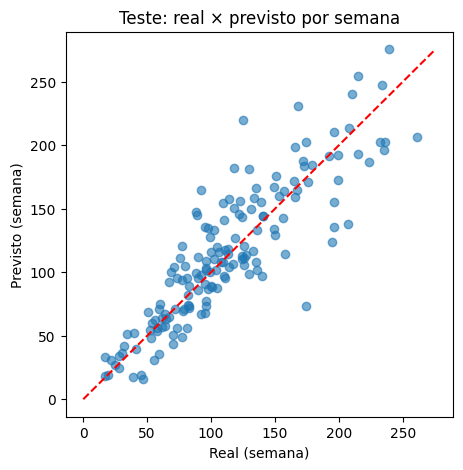

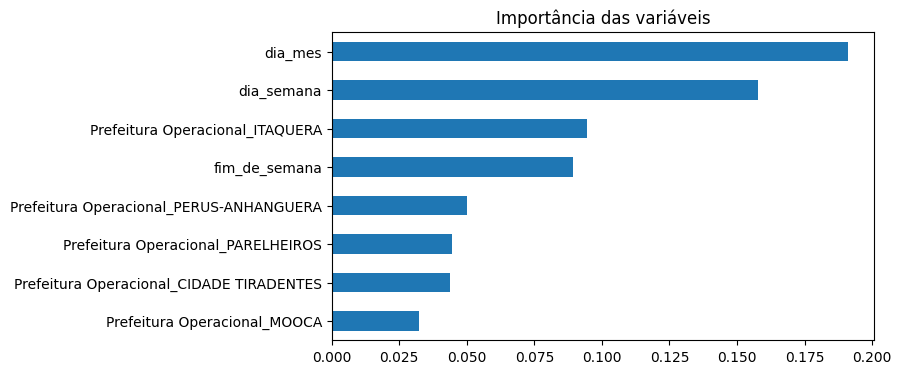

In [11]:
dt = dados[~tr].copy(); dt['previsto'] = m.predict(X_te)
sem = dt.groupby(['semana','Prefeitura Operacional'])[['solicitacoes','previsto']].sum()
print('Semanal:', {k: round(v,3) for k,v in met(sem.solicitacoes, sem.previsto).items()})

plt.figure(figsize=(5,5))
plt.scatter(sem.solicitacoes, sem.previsto, alpha=.6)
mx = sem.values.max(); plt.plot([0,mx],[0,mx],'r--')
plt.xlabel('Real (semana)'); plt.ylabel('Previsto (semana)'); plt.title('Teste: real × previsto por semana')
plt.show()

pd.Series(m.feature_importances_, X.columns).sort_values().tail(8).plot.barh(figsize=(7,4), title='Importância das variáveis')
plt.show()

## 11. Exportação do modelo
Salvamos o modelo treinado em um arquivo (joblib), que será usado pelo serviço Python integrado à API em C# para responder à rota /previsao?regiao=...

In [12]:
import joblib
from google.colab import files
joblib.dump({'modelo': m, 'colunas': list(X.columns)}, 'modelo_random_forest.joblib')
files.download('modelo_random_forest.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusões

**Overfitting:** o modelo teve R² de 0,947 no treino e 0,439 no teste, e o erro médio (MAE) foi de 1,93 para 6,62 solicitações por dia. Isso indica overfitting: o Random Forest ajustou demais os dados de treino. A validação cruzada já mostrava o mesmo (MAE 1,91 no treino contra 5,64 na validação).

**Comparação com o modelo simples:** a média histórica por região e dia da semana teve MAE de 6,378 e R² de 0,49 no teste, ficando à frente do Random Forest na previsão diária. Com apenas três meses de dados, o modelo não superou a regra simples.

**Visão semanal:** somando por semana, o desempenho melhora (R² 0,74, MAE 20,1 para uma média de cerca de 112 solicitações por região por semana). Esse é o nível em que a previsão é útil para planejar equipes.

**O que significa para o cidadão:** a previsão semanal ajuda a prefeitura a direcionar equipes de limpeza e coleta para onde haverá mais pedidos, mas a previsão diária ainda não é confiável. As solicitações caem nos fins de semana, e eventos atípicos (como Butantã em 09/08) não são previsíveis, por isso o monitoramento em tempo real das lixeiras continua essencial. Solicitações não medem o volume real de lixo, então o modelo deve apoiar o planejamento e não substituir a avaliação das equipes.